# Evaluate classifiers

<!-- markdownlint-disable MD033-->
<div class="page-subtitle">
Using metrics, confusion matrices and visual checks to understand model errors
</div>
<!-- markdownlint-enable MD033 -->

---

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HendrikWulf/sds320-jb/blob/main/book/04_lessons/L05/06_evaluation-and-confusion-matrices.ipynb)

---

## 1. Motivation

A single accuracy number is easy to report and easy to misread. A model can post a respectable overall accuracy while consistently failing on one class you actually care about. This page gives you the tools to catch that.

---

## 2. Core idea

Aggregate {term}`accuracy <Accuracy>` tells you how often a model is right on average; per-class metrics and a {term}`confusion matrix <Confusion Matrix>` tell you where and how it is wrong.

A good evaluation combines:

- overall performance,
- per-class metrics,
- raw confusion matrix,
- normalised confusion matrix,
- visual inspection of predictions.

---

## 3. Workflow

:::{note} Previous code
:class: dropdown

This page assumes that `result` is the trained ResNet-50 output from the previous page.

In [4]:
# Import training functions and data

from geoai.recognize import train_image_classifier
import os
from pathlib import Path
from geoai.utils import download_file
import matplotlib.pyplot as plt
from geoai.recognize import (
    train_image_classifier,
    plot_training_history,
)

DATA_DIR = Path("data/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)

url = "https://data.source.coop/giuz/sds320/L05/data/EuroSAT-RGB.zip"
data_dir = download_file(url, output_path=str(DATA_DIR / Path(url).name))


In [ ]:
# Train a ResNet-50 classifier (~15 min)

result = train_image_classifier(
    data_dir=data_dir,
    model_name="resnet50",
    num_epochs=5,
    batch_size=32,
    learning_rate=1e-3,
    image_size=64,
    in_channels=3,
    pretrained=True,
    output_dir="image_recognition_output/resnet50",
    num_workers=4,
    seed=42,
)


GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model   │ ResNet           │ 23.5 M │ train │     0 │
│ 1 │ loss_fn │ CrossEntropyLoss │      0 │ train │     0 │
└───┴─────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 23.5 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 23.5 M                                                                                               
Total estimated model params size (MB): 94.114                                                                     
Modules in train mode: 218                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

Metric val_acc improved. New best score: 0.948
Epoch 0, global step 540: 'val_acc' reached 0.94815 (best 0.94815), saving model to '/Users/wulf/Documents/Documents_work/SDS/02_teaching/01_courses/SDS320/26HS_SDS320/06_jupyter_book/sds320-jb/book/04_lessons/L05/image_recognition_output/resnet50/models/resnet50_epoch=00_val_acc=0.9481.ckpt' as top 1


...

Metric val_acc improved by 0.005 >= min_delta = 0.0. New best score: 0.953
Epoch 2, global step 1620: 'val_acc' reached 0.95301 (best 0.95301), saving model to '/Users/wulf/Documents/Documents_work/SDS/02_teaching/01_courses/SDS320/26HS_SDS320/06_jupyter_book/sds320-jb/book/04_lessons/L05/image_recognition_output/resnet50/models/resnet50_epoch=02_val_acc=0.9530.ckpt' as top 1


Epoch 3, global step 2160: 'val_acc' was not in top 1


Metric val_acc improved by 0.003 >= min_delta = 0.0. New best score: 0.956
Epoch 4, global step 2700: 'val_acc' reached 0.95648 (best 0.95648), saving model to '/Users/wulf/Documents/Documents_work/SDS/02_teaching/01_courses/SDS320/26HS_SDS320/06_jupyter_book/sds320-jb/book/04_lessons/L05/image_recognition_output/resnet50/models/resnet50_epoch=04_val_acc=0.9565.ckpt' as top 1
`Trainer.fit` stopped: `max_epochs=5` reached.


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_acc          │    0.9561111330986023     │
│         test_loss         │    0.1441044956445694     │
└───────────────────────────┴───────────────────────────┘

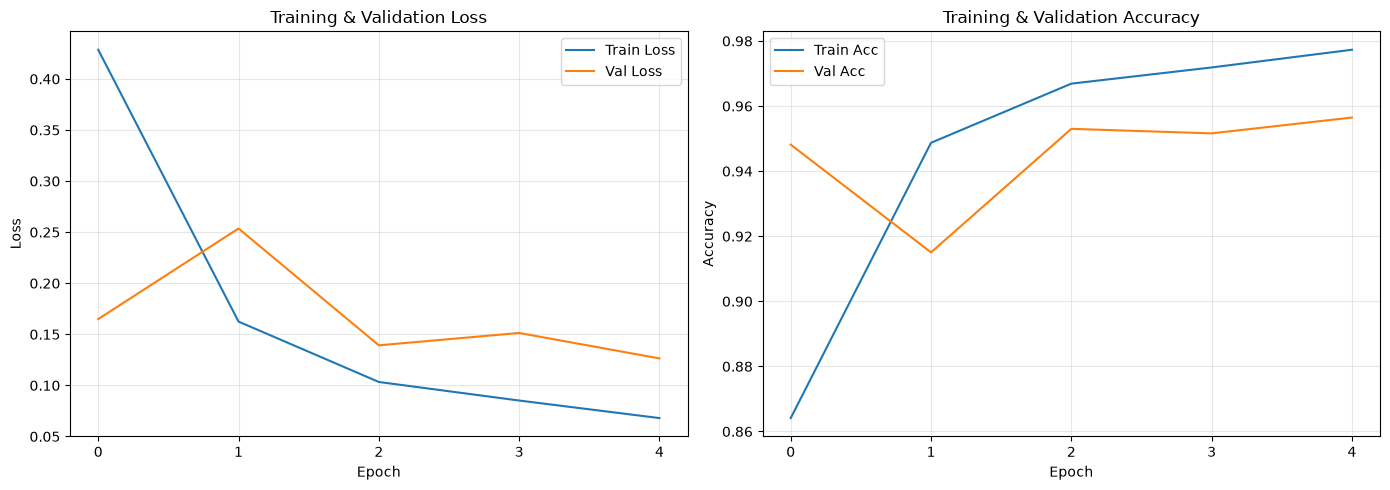

In [5]:
# Plot training history

fig = plot_training_history("image_recognition_output/resnet50/models")
plt.show()

:::

### A. Import evaluation functions

In [6]:
import random

import matplotlib.pyplot as plt

from geoai.recognize import (
    evaluate_classifier,
    predict_images,
    plot_confusion_matrix,
    plot_predictions,
)

### B. Evaluate on the test set

`evaluate_classifier` runs the trained model on held-out test images it never saw during training or validation, and returns overall accuracy, a full classification report, and a confusion matrix array.

In [7]:
eval_result = evaluate_classifier(
    model=result["model"],
    dataset=result["test_dataset"],
    class_names=result["class_names"],
)

Evaluating:   0%|          | 0/169 [00:32<?, ?it/s]

The returned dictionary contains the overall accuracy, a classification report and a confusion matrix.

In [8]:
eval_result.keys()

dict_keys(['accuracy', 'classification_report', 'confusion_matrix', 'per_class_accuracy'])

### C. Interpret per-class metrics

For each class, the classification report includes {term}`precision <Precision>` (of everything predicted as this class, what fraction actually is), {term}`recall <Recall>` (of everything that truly is this class, what fraction was correctly found), {term}`F1-score`, the harmonic mean of the two, and support, simply the number of test images in that class.

| Metric | Question it answers |
| --- | --- |
| {term}`Precision` | When the model predicts this class, how often is it correct? |
| {term}`Recall` | Of all true examples of this class, how many did the model find? |
| {term}`F1-score` | How well do precision and recall balance? |
| Support | How many test examples belong to this class? |

Use support when interpreting class-level results. A metric based on few examples is less stable than one based on many examples.

As a concrete example: if the test set contains 300 `Forest` tiles, the model correctly predicts `Forest` for 280 of them (recall = 280/300 ≈ 0.93), and also mislabels 10 `HerbaceousVegetation` tiles as `Forest` (precision = 280/290 ≈ 0.97). The F1-score works out to roughly 0.95, and the support is 300.

### D. Plot the confusion matrix

A {term}`Confusion Matrix` shows every combination of true class (rows) and predicted class (columns); diagonal cells are correct predictions, off-diagonal cells are errors. Raw counts show where the largest number of errors occurs.

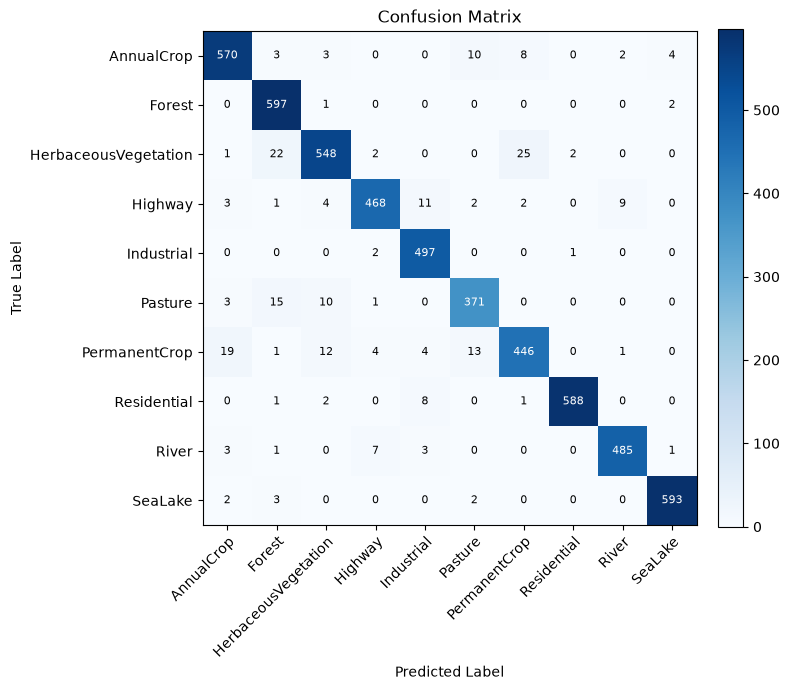

In [9]:
fig = plot_confusion_matrix(
    eval_result["confusion_matrix"],
    result["class_names"],
)
plt.show()

A normalized version (`normalize=True`) divides each row by its total, showing error *rates* instead, which is more informative when class sizes differ.

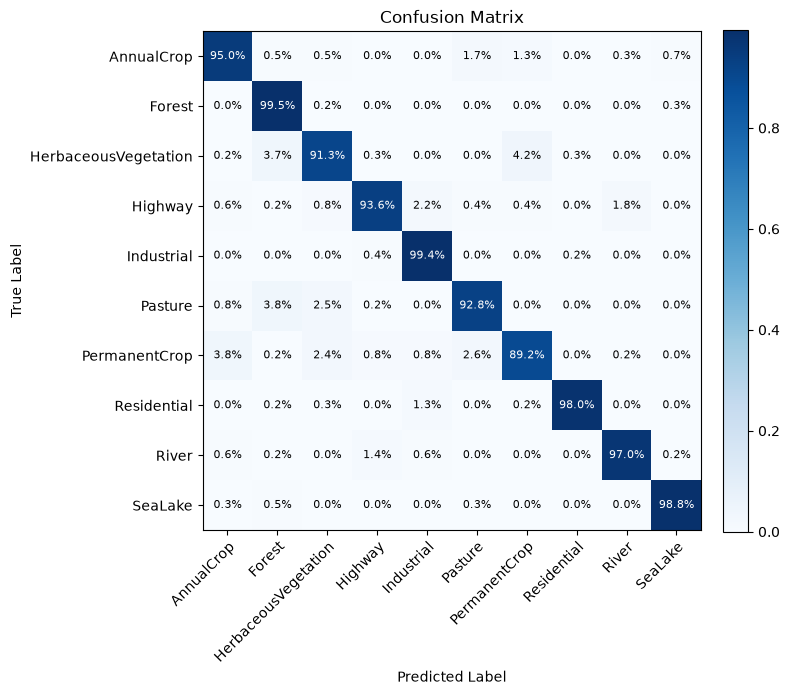

In [10]:
fig = plot_confusion_matrix(
    eval_result["confusion_matrix"],
    result["class_names"],
    normalize=True,
)
plt.show()

Look for off-diagonal hotspots: a bright cell at row `AnnualCrop`, column `PermanentCrop` means many annual-crop tiles were predicted as permanent crop, which fits the visual similarity you noticed between those two classes on the [ImageFolder & EuroSAT page](04_imagefolder-and-eurosat.md).

### E. Visualise predictions

Numbers and matrices are useful, but seeing the actual tiles a model got wrong is often the fastest way to understand *why*. `predict_images` runs inference on a sample, and `plot_predictions` displays it with predicted and true labels side by side.

Predicting:   0%|          | 0/1 [00:00<?, ?it/s]

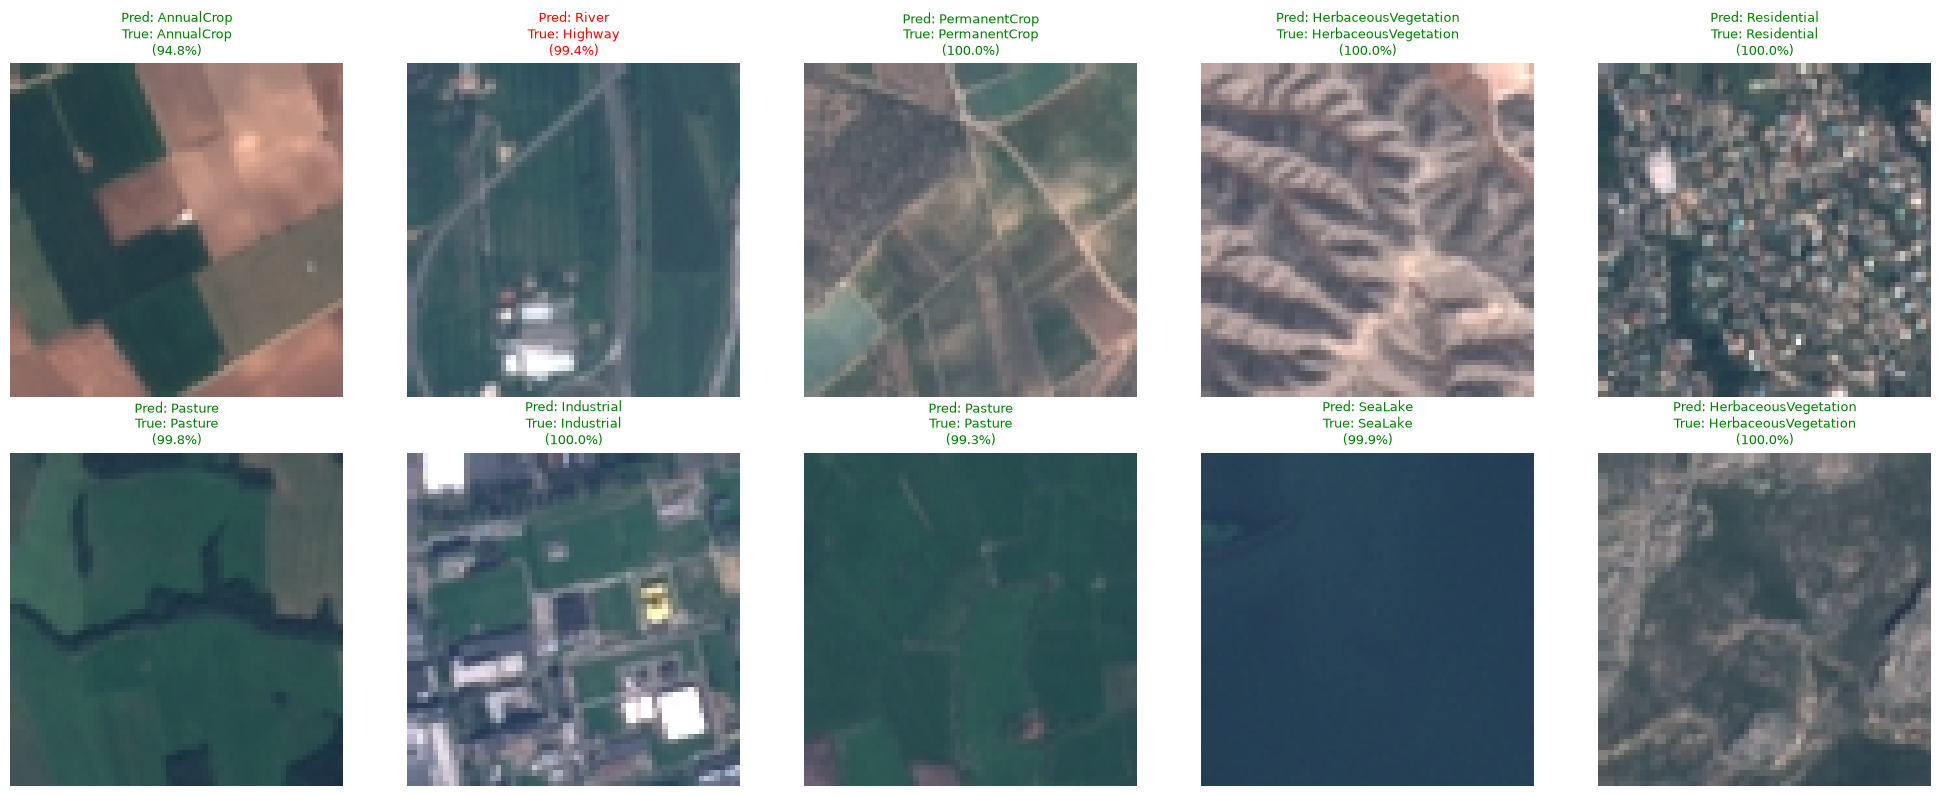

In [16]:
test_dataset = result["test_dataset"]
test_paths = test_dataset.image_paths
test_labels = test_dataset.labels

n_samples = min(10, len(test_paths))

rng = random.Random(43)
sample_indices = rng.sample(range(len(test_paths)), k=n_samples)
sample_paths = [test_paths[i] for i in sample_indices]
sample_labels = [test_labels[i] for i in sample_indices]

pred_result = predict_images(
    model=result["model"],
    image_paths=sample_paths,
    class_names=result["class_names"],
    image_size=64,
    in_channels=3,
)

fig = plot_predictions(
    image_paths=sample_paths,
    predictions=pred_result["predictions"],
    true_labels=sample_labels,
    class_names=result["class_names"],
    probabilities=pred_result["probabilities"],
)
plt.show()

Correct predictions are typically shown with a green title, misclassifications in red, giving you a quick visual scan of successes and failures together.

```{admonition} A confusing pair is not always a bug
:class: note
If `AnnualCrop` and `PermanentCrop` get confused often, that may reflect genuine visual similarity at 64×64 pixels rather than a problem with your model or training setup. Distinguishing "the model is broken" from "these classes are genuinely hard to tell apart" is exactly what per-class metrics and the confusion matrix are for.
```

---

## 4. Python activation

`rng.sample(range(len(test_paths)), k=10)` combines a fixed random seed with list indexing; fixing the seed here means your sample of inspected predictions is reproducible across runs, which matters if you want to compare the same tiles across two trained models later.

---

## 5. Common pitfalls

- **Reporting only overall accuracy.** It can look strong while hiding a class the model handles badly; always check the per-class report too.
- **Only ever looking at the raw confusion matrix.** Raw counts are dominated by class size; the normalized version is usually more informative for comparing how *hard* each class is.
- **Skipping visual inspection.** Numbers tell you a class is confused; looking at the actual tiles often tells you *why*.

---

## 6. Mini task

Using the confusion matrix from your own trained model (or reasoning from the `AnnualCrop`/`PermanentCrop` example above if you have not trained one yet), name one class pair you would expect to be confused, and explain what about the classes themselves would cause it.

:::{note} Sample solution
:class: dropdown

`HerbaceousVegetation` and `Forest` are a likely confused pair: both classes are dominated by green, textured vegetation at 64×64 pixels, and the boundary between "sparse tree cover" and "dense herbaceous vegetation" is genuinely ambiguous in some tiles, not just a model weakness. Checking a handful of the actual misclassified tiles with `plot_predictions` would confirm whether the confusion tracks this kind of visual ambiguity or points to something else, such as a labeling inconsistency in the source dataset.
:::

---

## 7. Key takeaways

- Overall accuracy can hide serious class-level problems; always check per-class precision, recall, and F1-score too.
- A confusion matrix's off-diagonal cells reveal exactly which classes get mixed up, and how often.
- Normalized confusion matrices show error rates rather than raw counts, which is more informative when class sizes differ.
- Visualizing actual predicted images connects abstract metrics back to real tiles, and helps you judge whether a confusion is a modeling problem or a genuinely hard case.